# 03. Pipeline reproducible: entrenamiento, evaluación, segmentación y predicción
### Detección temprana de abandono de clientes (*Customer Churn*)

Este notebook documenta **paso a paso cómo se entrenó el modelo, qué hizo y cómo se hizo**, usando el código del paquete `src/churn/`
(el mismo que ejecuta `python -m churn.train`). A diferencia de los notebooks 01 y 02, aquí todo el preprocesamiento vive dentro de un
`Pipeline` de scikit-learn, de modo que la imputación y el escalado se calculan **solo con los datos de entrenamiento** (sin *data leakage*).

**Contenido**
1. Carga y diagnóstico de los datos
2. Limpieza y partición estratificada
3. Pipeline de preprocesamiento
4. Entrenamiento y validación cruzada (Regresión Logística vs XGBoost)
5. Evaluación en el conjunto de prueba
6. Variables más influyentes
7. Segmentación de clientes (K-Means)
8. Predicción con el modelo guardado
9. Cómo reproducirlo

In [1]:
import sys, tempfile, warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore")

# El notebook se ejecuta desde notebooks/; el paquete vive en ../src (o instalado con `pip install -e .`).
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from churn import config
from churn.data import load_raw, split_features_target, standardize_categories, train_test_split_stratified
from churn.evaluate import compute_metrics, select_best_model
from churn.features import build_preprocessor
from churn.modeling import build_models
from churn.predict import load_artifacts, predict_customers
from churn.reporting import plot_confusion_matrices, plot_roc_curves
from churn.segment import assign_segments, describe_segments, fit_segmenter, profile_segments
from sklearn.model_selection import StratifiedKFold, cross_validate

pd.set_option("display.width", 140)
print("Paquete churn cargado correctamente.")

Paquete churn cargado correctamente.


## 1. Carga y diagnóstico de los datos

Se lee el CSV original (`data/raw/`, **inmutable**). Se revisan tamaño, duplicados, valores nulos y el balance de la variable objetivo.

In [2]:
raw = load_raw()
print(f"Dimensiones: {raw.shape[0]} clientes x {raw.shape[1]} columnas")
print(f"IDs duplicados: {raw[config.ID_COL].duplicated().sum()}")
print(f"Tasa de churn: {raw[config.TARGET].mean():.2%}  ({raw[config.TARGET].sum()} desertores)")

nulos = raw.isna().sum()
nulos[nulos > 0].sort_values(ascending=False).to_frame("nulos")

Dimensiones: 5630 clientes x 20 columnas
IDs duplicados: 0
Tasa de churn: 16.84%  (948 desertores)


,nulos
DaySinceLastOrder,307
OrderAmountHikeFromlastYear,265
Tenure,264
OrderCount,258
CouponUsed,256
HourSpendOnApp,255
WarehouseToHome,251


**Lectura:** el dataset tiene ~17 % de desertores (clases **desbalanceadas**) y varias columnas numéricas con ~250-300 nulos.
Por eso los modelos usan ponderación de clases y la imputación se hace dentro del pipeline.

## 2. Limpieza y partición estratificada

- Se unifican etiquetas duplicadas (`Phone`→`Mobile Phone`, `CC`→`Credit Card`, `COD`→`Cash on Delivery`, `Mobile`→`Mobile Phone`).
  Los nulos **no** se imputan aquí.
- Partición **80 % entrenamiento / 20 % prueba**, estratificada y con `random_state=42`.

In [3]:
clean = standardize_categories(raw)
X, y = split_features_target(clean)
X_train, X_test, y_train, y_test = train_test_split_stratified(X, y)

print(f"Entrenamiento: {len(X_train)} clientes ({y_train.mean():.2%} churn)")
print(f"Prueba:        {len(X_test)} clientes ({y_test.mean():.2%} churn)")
print("\nCategorías tras la limpieza:")
for col in config.CATEGORICAL_COLUMNS:
    print(f"  {col}: {sorted(clean[col].unique())}")

Entrenamiento: 4504 clientes (16.83% churn)
Prueba:        1126 clientes (16.87% churn)

Categorías tras la limpieza:
  PreferredLoginDevice: ['Computer', 'Mobile Phone']
  PreferredPaymentMode: ['Cash on Delivery', 'Credit Card', 'Debit Card', 'E wallet', 'UPI']
  Gender: ['Female', 'Male']
  PreferedOrderCat: ['Fashion', 'Grocery', 'Laptop & Accessory', 'Mobile Phone', 'Others']
  MaritalStatus: ['Divorced', 'Married', 'Single']


## 3. Pipeline de preprocesamiento

| Tipo | Columnas | Transformación |
| --- | --- | --- |
| Numéricas (13) | `Tenure`, `DaySinceLastOrder`, `OrderCount`, `CashbackAmount`, ... | Imputación por **mediana** (+ `StandardScaler` solo para la regresión logística) |
| Categóricas (5) | `PreferredLoginDevice`, `PreferredPaymentMode`, `Gender`, `PreferedOrderCat`, `MaritalStatus` | **One-Hot Encoding** (categorías nuevas se ignoran) |

`CustomerID` y `Churn` no entran como predictoras.

In [4]:
preprocesador = build_preprocessor(scale=True).fit(X_train)
X_train_transformado = preprocesador.transform(X_train)
print(f"Matriz de entrenamiento transformada: {X_train_transformado.shape}  (nulos: {int(np.isnan(X_train_transformado).sum())})")
print("Primeras columnas resultantes:", [n.split('__', 1)[1] for n in preprocesador.get_feature_names_out()[:8]], "...")

Matriz de entrenamiento transformada: (4504, 30)  (nulos: 0)


Primeras columnas resultantes: ['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain'] ...


## 4. Entrenamiento y validación cruzada

Dos modelos con el mismo preprocesamiento:

- **Regresión Logística** (base, interpretable): `class_weight='balanced'` para penalizar más no detectar a un desertor.
- **XGBoost** (avanzado, no lineal): `n_estimators=150`, `max_depth=4`, `learning_rate=0.05` y `scale_pos_weight` = retenidos / desertores.

Antes de tocar el conjunto de prueba, cada modelo se valida con **validación cruzada estratificada de 5 particiones** sobre el entrenamiento
para medir la estabilidad de su desempeño.

In [5]:
modelos = build_models(y_train)
cv = StratifiedKFold(n_splits=config.CV_FOLDS, shuffle=True, random_state=config.RANDOM_STATE)

filas = []
cv_resumen = {}
for nombre, modelo in modelos.items():
    scores = cross_validate(modelo, X_train, y_train, cv=cv,
                            scoring=["recall", "precision", "f1", "roc_auc"])
    cv_resumen[nombre] = {"recall_mean": scores["test_recall"].mean(), "roc_auc_mean": scores["test_roc_auc"].mean()}
    filas.append({
        "Modelo": nombre,
        **{m: f"{scores[f'test_{m}'].mean():.3f} ± {scores[f'test_{m}'].std():.3f}"
           for m in ["recall", "precision", "f1", "roc_auc"]},
    })
pd.DataFrame(filas).set_index("Modelo")

,recall,precision,f1,roc_auc
Modelo,,,,
Regresion Logistica,0.814 ± 0.048,0.464 ± 0.021,0.591 ± 0.024,0.890 ± 0.013
XGBoost,0.856 ± 0.044,0.649 ± 0.012,0.738 ± 0.023,0.947 ± 0.011


In [6]:
# Entrenamiento final de cada modelo con TODO el conjunto de entrenamiento
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    print(f"{nombre}: entrenado")

Regresion Logistica: entrenado


XGBoost: entrenado


## 5. Evaluación en el conjunto de prueba

En churn se prioriza el **Recall**: dejar ir a un cliente que se iba a fugar cuesta más que enviar una promoción a alguien que se iba a quedar.
El modelo seleccionado es el de mayor Recall **medio en validación cruzada** (desempate por ROC-AUC): así el conjunto de prueba se reserva para el reporte final y no interviene en la elección.

In [7]:
probs = {n: m.predict_proba(X_test)[:, 1] for n, m in modelos.items()}
metricas = {n: compute_metrics(y_test, (probs[n] >= config.DECISION_THRESHOLD).astype(int), probs[n]) for n in modelos}
seleccionado = select_best_model(cv_resumen, recall_key="recall_mean", auc_key="roc_auc_mean")

tabla = pd.DataFrame(metricas).T
porcentajes = ["accuracy", "recall", "precision", "f1", "roc_auc"]
tabla[porcentajes] = (tabla[porcentajes] * 100).round(2)
tabla = tabla.astype({c: int for c in ["tp", "fn", "fp", "tn"]})
print(f"Modelo seleccionado: {seleccionado}")
tabla

Modelo seleccionado: XGBoost


,accuracy,recall,precision,f1,roc_auc,tp,fn,fp,tn
Regresion Logistica,79.22,84.74,43.99,57.91,88.51,161,29,205,731
XGBoost,89.79,90.53,63.94,74.95,95.65,172,18,97,839


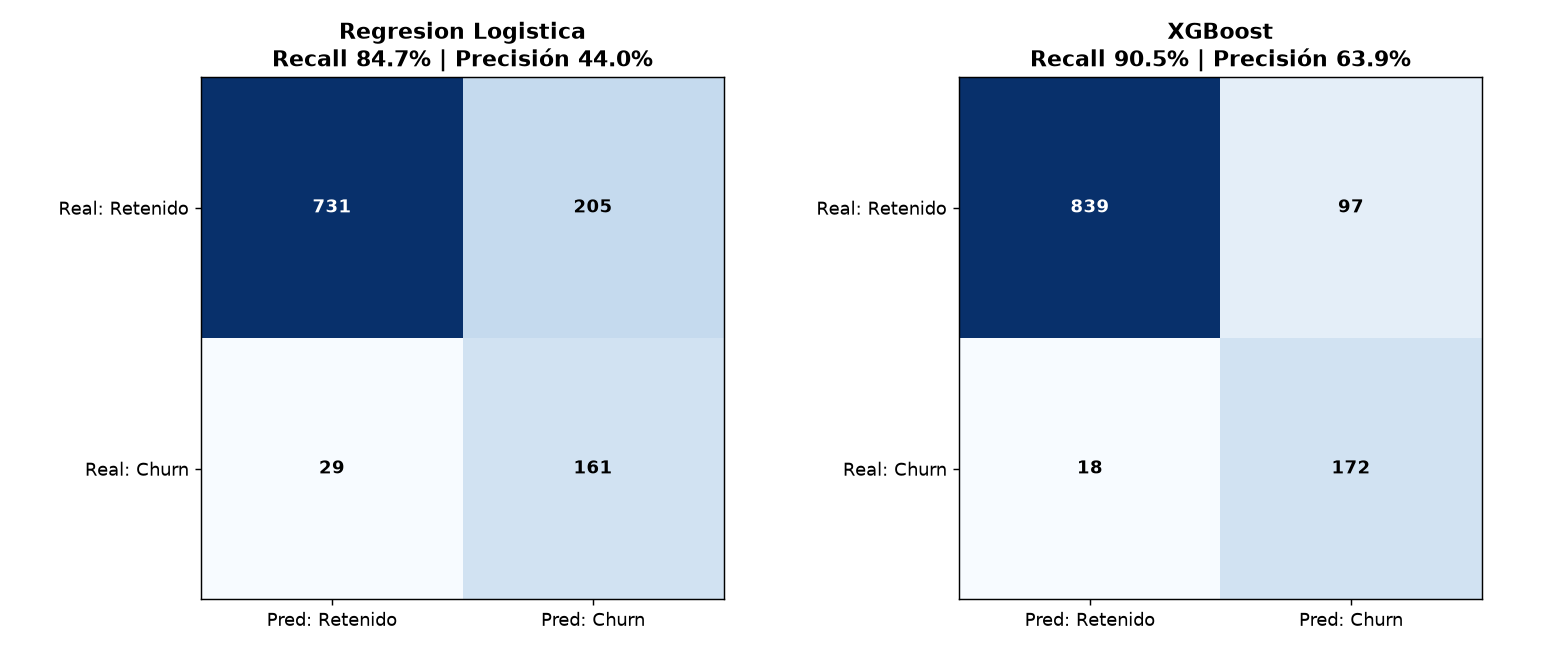

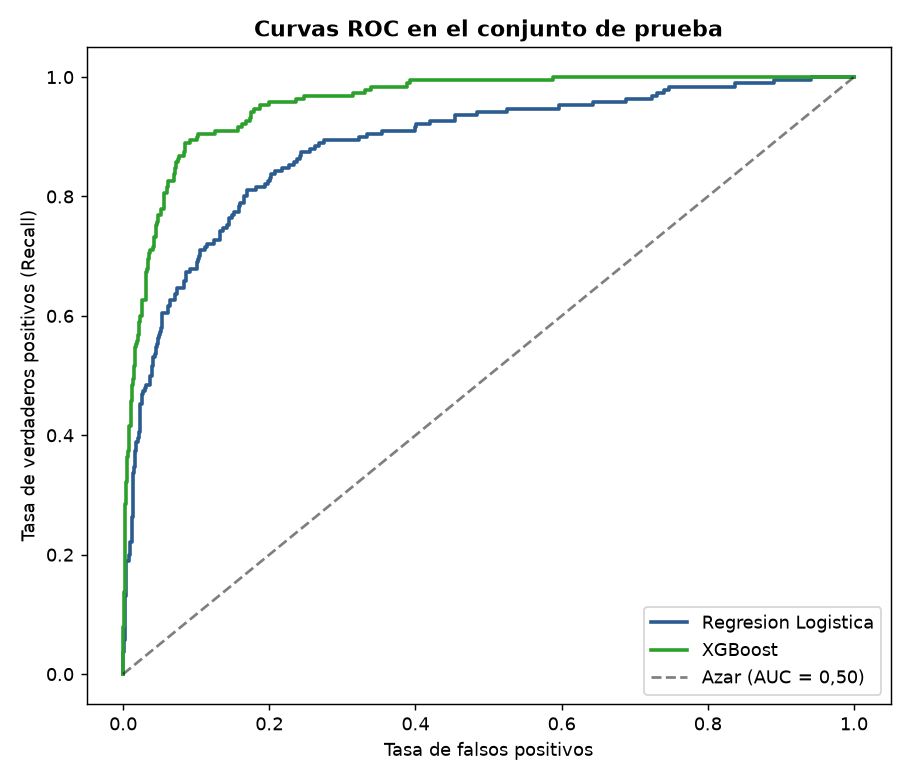

In [8]:
with tempfile.TemporaryDirectory() as tmp:
    display(Image(filename=plot_confusion_matrices(metricas, Path(tmp) / "cm.png")))
    display(Image(filename=plot_roc_curves(y_test, probs, Path(tmp) / "roc.png")))

**Lectura:** XGBoost detecta más desertores que la regresión logística y con mucha menos "falsa alarma" (mayor precisión),
por lo que es el modelo que se guarda para producción.

## 6. Variables más influyentes

Importancia de variables de XGBoost (las que más reducen el error al dividir los árboles) y |coeficientes| de la regresión logística.

In [9]:
def pesos(nombre):
    pipe = modelos[nombre]
    columnas = [n.split("__", 1)[1] for n in pipe.named_steps["preprocess"].get_feature_names_out()]
    est = pipe.named_steps["model"]
    valores = est.feature_importances_ if nombre == "XGBoost" else np.abs(est.coef_[0])
    return pd.Series(valores, index=columnas).sort_values(ascending=False).head(10)

pd.concat({n: pesos(n).round(4).reset_index().rename(columns={"index": "variable", 0: "peso"}) for n in modelos}, axis=1)

Regresion Logistica                                      XGBoost        
                                variable    peso                             variable    peso
0                PreferedOrderCat_Others  2.2816                               Tenure  0.1631
1    PreferedOrderCat_Laptop & Accessory  1.8763                             Complain  0.0685
2                                 Tenure  1.5208  PreferedOrderCat_Laptop & Accessory  0.0588
3                         CashbackAmount  0.9771                 MaritalStatus_Single  0.0520
4          PreferedOrderCat_Mobile Phone  0.9667                    SatisfactionScore  0.0464
5                               Complain  0.7206                       CashbackAmount  0.0458
6                        NumberOfAddress  0.5970                             CityTier  0.0438
7                   MaritalStatus_Single  0.5340                    DaySinceLastOrder  0.0406
8  PreferredPaymentMode_Cash on Delivery  0.4604             PreferedOrderCat_Fashion  0.0391
9                      DaySinceLastOrder  0.4153     PreferredPaymentMode_Credit Card  0.0366

## 7. Segmentación de clientes (K-Means)

Además de predecir el abandono, se **agrupan los clientes por comportamiento** usando antigüedad, recencia, frecuencia y gasto
(`Tenure`, `DaySinceLastOrder`, `OrderCount`, `CashbackAmount`). **No se usa la etiqueta `Churn`**: el churn real se muestra solo para
interpretar cada grupo. El número de segmentos `k` se elige con el coeficiente de silueta.

In [10]:
segmentador, info = fit_segmenter(clean)
etiquetas = assign_segments(segmentador, clean)
perfil = profile_segments(clean, etiquetas)

print("Silueta por k:", {k: round(v, 3) for k, v in info["silhouette_by_k"].items()}, "-> k elegido =", info["k"])
perfil.assign(perfil_resumen=pd.Series(describe_segments(perfil)))

Silueta por k: {3: 0.374, 4: 0.333, 5: 0.318, 6: 0.33} -> k elegido = 3


,clientes,tasa_churn,Tenure,DaySinceLastOrder,OrderCount,CashbackAmount,perfil_resumen
segmento,,,,,,,
0,3480,0.2213,5.84,3.12,1.79,154.21,"antigüedad menor (-42%), días sin comprar meno..."
1,1236,0.0356,20.45,5.58,2.30,227.30,"antigüedad mayor (+105%), días sin comprar may..."
2,914,0.1466,11.65,8.92,8.42,197.13,"antigüedad mayor (+17%), días sin comprar mayo..."


## 8. Predicción con el modelo guardado

`python -m churn.train` guarda el pipeline completo en `models/churn_model.joblib`. Aquí se carga y se usa como lo haría un sistema real:
recibe filas con las columnas del dataset y devuelve **probabilidad de churn, clase, nivel de riesgo y segmento**.

In [11]:
modelo_guardado, segmentador_guardado = load_artifacts()
muestra = raw.sample(8, random_state=7)
prediccion = predict_customers(muestra, modelo_guardado, segmentador_guardado)
prediccion.assign(churn_real=muestra[config.TARGET].to_numpy())

,CustomerID,churn_probability,churn_prediction,risk_level,segment,churn_real
0,51356,0.0207,0,Bajo,0,0
1,54953,0.8027,1,Alto,0,1
2,50195,0.3001,0,Bajo,2,0
3,52504,0.0556,0,Bajo,0,0
4,52763,0.0820,0,Bajo,0,0
5,50346,0.5093,1,Medio,0,0
6,53764,0.0743,0,Bajo,0,0
7,52605,0.0154,0,Bajo,0,0


In [12]:
todos = predict_customers(raw, modelo_guardado, segmentador_guardado)
print("Distribución de clientes por nivel de riesgo (modelo evaluado sobre toda la base):")
print(todos["risk_level"].value_counts().reindex(["Alto", "Medio", "Bajo"]).to_string())
todos.sort_values("churn_probability", ascending=False).head(10)

Distribución de clientes por nivel de riesgo (modelo evaluado sobre toda la base):
risk_level
Alto      921
Medio     594
Bajo     4115


,CustomerID,churn_probability,churn_prediction,risk_level,segment
2837,52838,0.9907,1,Alto,0
4287,54288,0.9907,1,Alto,0
3147,53148,0.9897,1,Alto,0
4617,54618,0.9897,1,Alto,0
3601,53602,0.9882,1,Alto,0
3378,53379,0.9878,1,Alto,0
4848,54849,0.9878,1,Alto,0
4016,54017,0.9875,1,Alto,0
22,50023,0.9875,1,Alto,0
1472,51473,0.9875,1,Alto,0


> **Nota:** el modelo guardado se entrenó con el 80 % de los clientes; los clientes de entrenamiento muestran probabilidades optimistas.
> Las métricas de la sección 5 (conjunto de prueba) son las que reflejan el desempeño esperado en clientes nuevos.

## 9. Cómo reproducirlo

```bash
pip install -r requirements.txt && pip install -e .
python -m churn.train          # entrena, evalúa y regenera models/, reports/ y data/processed/
python -m churn.predict --input data/raw/ecommerce_data.csv --output predicciones.csv
pytest --cov=src --cov-report=term-missing
```

Resultados completos y gráficos: `reports/training_report.md`, `reports/metrics.json`, `reports/figures/`.